# Engine Remaining Useful Life (RUL) and health state — NASA C-MAPSS FD001

**Goal:** predict how many flight cycles an engine has left (regression), then turn that RUL into a
health state (multi-class): `healthy`, `warning`, `failure` (failure = fail or check immediately).

Notebook flow: data prep → EDA (target, correlation, mutual information) → split by engine →
regression models (linear regression, decision tree, random forest, XGBoost) with tuning → 5-fold cross-validation (mean ± std) → classification
metrics (F1, ROC AUC, confusion matrix) → choose the final model used in `train.py`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import (mean_squared_error, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
import xgboost as xgb

from health import (COLUMNS, FEATURES, RUL_CAP, STATES, load_test, rul_to_state_id, state_probabilities)

SEED = 1

## 1. Data preparation

In [2]:
df = pd.read_csv("data/train_FD001.txt", sep=r"\s+", header=None, names=COLUMNS)
print(df.shape)
df.head()

(20631, 26)


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


Each row is one flight cycle of one engine (`unit`). 21 sensors (`s1`–`s21`) and 3 operating
settings (`op1`–`op3`). In the training file every engine runs until it fails, so the **RUL** of a row
is `last cycle of that engine − current cycle`.

In [3]:
df["rul"] = df.groupby("unit")["cycle"].transform("max") - df["cycle"]
df["rul_capped"] = df["rul"].clip(upper=RUL_CAP)   # early life: RUL not predictable, cap at 125
df[["unit", "cycle", "rul", "rul_capped"]].head()

,unit,cycle,rul,rul_capped
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125


## 2. EDA

In [4]:
print("missing values:", df.isnull().sum().sum())
print("engines:", df.unit.nunique(), "| rows:", len(df))
df.describe().T

missing values: 0
engines: 100 | rows: 20631


,count,mean,std,min,25%,50%,75%,max
unit,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
op1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
op2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
op3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
s1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
s2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
s3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
s4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
s5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200


count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


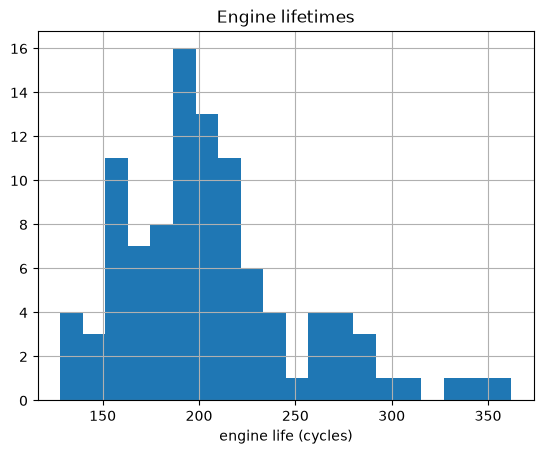

In [5]:
life = df.groupby("unit")["cycle"].max()
print(life.describe())
life.hist(bins=20); plt.xlabel("engine life (cycles)"); plt.title("Engine lifetimes"); plt.show()

Sensors/settings with zero variance carry no information — they are dropped (`health.CONSTANT_COLUMNS`).

In [6]:
std = df.drop(columns=["unit", "cycle", "rul", "rul_capped"]).std()
print("constant columns:", list(std[std == 0].index))
print("features used  :", FEATURES)

constant columns: ['op3', 's1', 's10', 's18', 's19']
features used  : ['cycle', 'op1', 'op2', 's2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


### Target: RUL and health states

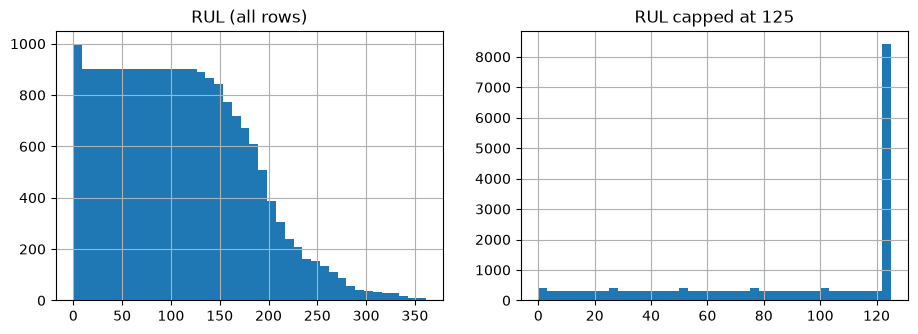

failure (<=50 cycles left) | warning (51-100) | healthy (>100)


state
failure    0.247
warning    0.242
healthy    0.510
Name: proportion, dtype: float64

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["rul"].hist(bins=40, ax=ax[0]); ax[0].set_title("RUL (all rows)")
df["rul_capped"].hist(bins=40, ax=ax[1]); ax[1].set_title(f"RUL capped at {RUL_CAP}")
plt.show()

df["state"] = [STATES[i] for i in rul_to_state_id(df["rul"])]
print("failure (<=50 cycles left) | warning (51-100) | healthy (>100)")
df["state"].value_counts(normalize=True).reindex(STATES).round(3)

The classes are imbalanced (about half the rows are `healthy`) → we report **macro F1**, not only accuracy.

### Sensor behaviour over an engine's life

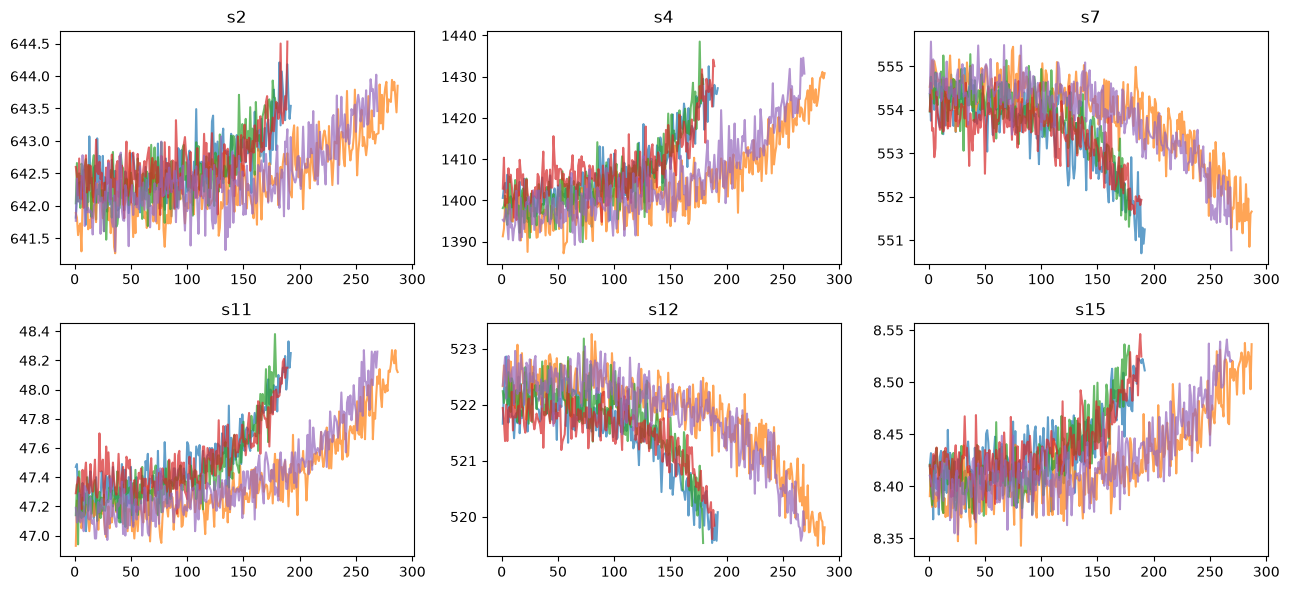

In [8]:
sens = ["s2", "s4", "s7", "s11", "s12", "s15"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, s in zip(axes.ravel(), sens):
    for u in [1, 2, 3, 4, 5]:
        e = df[df.unit == u]
        ax.plot(e["cycle"], e[s], alpha=.7)
    ax.set_title(s)
plt.tight_layout(); plt.show()

### Correlation with RUL

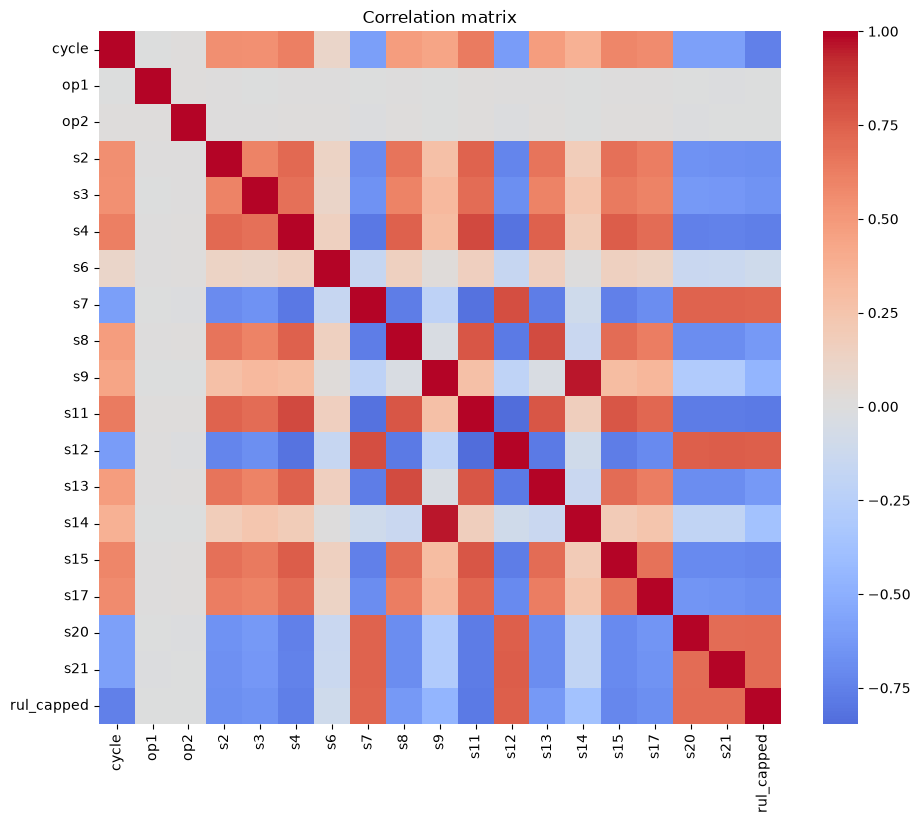

s11     -0.775230
s4      -0.757157
cycle   -0.746939
s15     -0.720858
s17     -0.680829
s2      -0.678458
s3      -0.655030
s8      -0.624568
s13     -0.624034
s9      -0.462151
s14     -0.369753
s6      -0.108289
op2     -0.007091
op1     -0.005556
s20      0.704626
s21      0.707334
s7       0.733021
s12      0.748870
Name: rul_capped, dtype: float64

In [9]:
corr = df[FEATURES + ["rul_capped"]].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation matrix"); plt.show()

corr["rul_capped"].drop("rul_capped").sort_values()

### Feature importance — mutual information

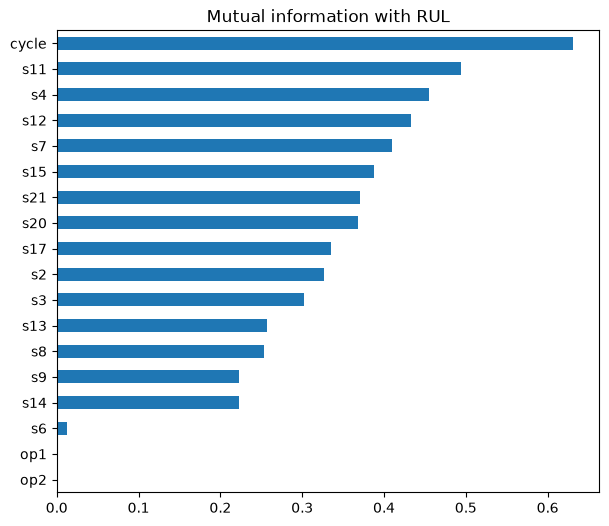

cycle    0.631
s11      0.494
s4       0.455
s12      0.433
s7       0.409
s15      0.388
s21      0.371
s20      0.369
s17      0.335
s2       0.326
s3       0.303
s13      0.257
s8       0.253
s9       0.223
s14      0.222
s6       0.013
op1      0.000
op2      0.000
dtype: float64

In [10]:
mi = mutual_info_regression(df[FEATURES], df["rul_capped"], random_state=SEED)
mi = pd.Series(mi, index=FEATURES).sort_values(ascending=False)
mi.plot.barh(figsize=(7, 6)).invert_yaxis(); plt.title("Mutual information with RUL"); plt.show()
mi.round(3)

## 3. Train / validation / test split — 60 / 20 / 20 by engine

Same recipe as the earlier projects: first `full_train` (80%) vs `test` (20%), then `train` (75% of
full_train = 60%) vs `validation` (20%). The only difference is that we split **engines**, not rows: rows
of one engine are near-duplicates, so a row-wise split would leak.

We also have the **official test set** (`test_FD001.txt` + `RUL_FD001.txt`): 100 other engines that stop
*before* failure. `RUL_FD001.txt` gives the true RUL after each engine's last recorded cycle, so the RUL of
every earlier cycle is `RUL_FD001 + (last cycle - cycle)` (`health.load_test`). The training file has no such
file, which is why we computed the training RUL ourselves. The official set is a second, fully external test.

In [11]:
df_full_train, df_test = (lambda g: (df.iloc[g[0]].copy(), df.iloc[g[1]].copy()))(
    next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(df, groups=df["unit"])))
df_train, df_val = (lambda g: (df_full_train.iloc[g[0]].copy(), df_full_train.iloc[g[1]].copy()))(
    next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(df_full_train, groups=df_full_train["unit"])))

df_official = load_test("data/test_FD001.txt", "data/RUL_FD001.txt")

for name, d in [("train", df_train), ("val", df_val), ("test", df_test),
                ("full_train", df_full_train), ("official test", df_official)]:
    print(f"{name:14} {d.unit.nunique():>3} engines {len(d):>6} rows")

X_train, X_val, X_test, X_off = (d[FEATURES] for d in (df_train, df_val, df_test, df_official))
y_train, y_val, y_test, y_off = (d["rul_capped"] for d in (df_train, df_val, df_test, df_official))

def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

print("baseline (predict the mean) val RMSE:", round(rmse(y_val, np.full(len(y_val), y_train.mean())), 2))

train           60 engines  12510 rows
val             20 engines   4153 rows
test            20 engines   3968 rows
full_train      80 engines  16663 rows
official test  100 engines  13096 rows
baseline (predict the mean) val RMSE: 41.65


## 4. Regression models (RMSE)

Linear regression (baseline, nothing to tune), decision tree, random forest and XGBoost; the last three
are tuned on the validation engines.

In [12]:
results = {}   # model name -> (fitted model, train rmse, val rmse)

# --- Linear regression (baseline)
m = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
tr, va = rmse(y_train, m.predict(X_train)), rmse(y_val, m.predict(X_val))
print(f"linear regression train={tr:.2f} val={va:.2f}")
results["Linear regression"] = (m, tr, va)

linear regression train=20.14 val=19.54


In [13]:
# --- Decision tree
best = None
for depth in [3, 5, 7, 10, 15]:
    for leaf in [10, 50]:
        m = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=SEED).fit(X_train, y_train)
        tr, va = rmse(y_train, m.predict(X_train)), rmse(y_val, m.predict(X_val))
        print(f"tree depth={depth:<3} leaf={leaf:<3} train={tr:.2f} val={va:.2f}")
        if best is None or va < best[2]: best = (m, tr, va, (depth, leaf))
results["Decision tree"] = best[:3]; print("best (depth, leaf):", best[3])

tree depth=3   leaf=10  train=20.77 val=20.45
tree depth=3   leaf=50  train=20.77 val=20.45
tree depth=5   leaf=10  train=17.91 val=17.71
tree depth=5   leaf=50  train=17.96 val=17.70
tree depth=7   leaf=10  train=16.46 val=18.05
tree depth=7   leaf=50  train=16.81 val=17.70
tree depth=10  leaf=10  train=14.58 val=18.21
tree depth=10  leaf=50  train=16.10 val=17.72
tree depth=15  leaf=10  train=12.62 val=19.11
tree depth=15  leaf=50  train=15.95 val=17.76
best (depth, leaf): (7, 50)


In [14]:
# --- Random forest
best = None
for depth in [6, 10, 15]:
    for leaf in [5, 20]:
        m = RandomForestRegressor(n_estimators=100, max_depth=depth, min_samples_leaf=leaf,
                                  n_jobs=-1, random_state=SEED).fit(X_train, y_train)
        tr, va = rmse(y_train, m.predict(X_train)), rmse(y_val, m.predict(X_val))
        print(f"rf depth={depth:<3} leaf={leaf:<3} train={tr:.2f} val={va:.2f}")
        if best is None or va < best[2]: best = (m, tr, va, (depth, leaf))
results["Random forest"] = best[:3]; print("best (depth, leaf):", best[3])

rf depth=6   leaf=5   train=16.04 val=16.42
rf depth=6   leaf=20  train=16.13 val=16.41
rf depth=10  leaf=5   train=12.91 val=15.91
rf depth=10  leaf=20  train=14.26 val=15.96
rf depth=15  leaf=5   train=10.08 val=15.82
rf depth=15  leaf=20  train=13.78 val=15.92
best (depth, leaf): (15, 5)


### XGBoost — and the over-fitting check
XGBoost can memorise the training engines. We control it with a small learning rate, shallow trees,
`min_child_weight`, row/column subsampling and **early stopping on the validation engines**, then
compare train vs validation RMSE.

In [15]:
best = None
for depth in [3, 4, 6]:
    for eta in [0.03, 0.1]:
        for mcw in [1, 10]:
            m = xgb.XGBRegressor(n_estimators=1000, learning_rate=eta, max_depth=depth,
                                 min_child_weight=mcw, subsample=0.8, colsample_bytree=0.8,
                                 early_stopping_rounds=30, random_state=SEED, n_jobs=-1)
            m.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)
            tr, va = rmse(y_train, m.predict(X_train)), rmse(y_val, m.predict(X_val))
            print(f"xgb depth={depth} eta={eta} mcw={mcw:<3} trees={m.best_iteration + 1:<4} train={tr:.2f} val={va:.2f}")
            if best is None or va < best[2]: best = (m, tr, va, (depth, eta, mcw))
results["XGBoost"] = best[:3]; xgb_best = best[0]; print("best (depth, eta, mcw):", best[3])

xgb depth=3 eta=0.03 mcw=1   trees=951  train=14.32 val=15.52
xgb depth=3 eta=0.03 mcw=10  trees=951  train=14.35 val=15.53
xgb depth=3 eta=0.1 mcw=1   trees=300  train=14.35 val=15.54
xgb depth=3 eta=0.1 mcw=10  trees=251  train=14.57 val=15.49
xgb depth=4 eta=0.03 mcw=1   trees=448  train=14.06 val=15.53
xgb depth=4 eta=0.03 mcw=10  trees=448  train=14.08 val=15.54
xgb depth=4 eta=0.1 mcw=1   trees=141  train=14.06 val=15.66
xgb depth=4 eta=0.1 mcw=10  trees=127  train=14.22 val=15.69
xgb depth=6 eta=0.03 mcw=1   trees=245  train=12.57 val=15.60
xgb depth=6 eta=0.03 mcw=10  trees=252  train=12.71 val=15.62
xgb depth=6 eta=0.1 mcw=1   trees=76   train=12.57 val=15.70
xgb depth=6 eta=0.1 mcw=10  trees=112  train=11.83 val=15.77
best (depth, eta, mcw): (3, 0.1, 10)


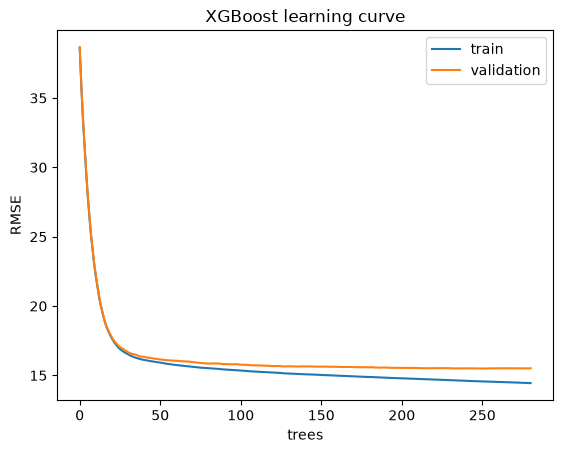

In [16]:
curve = xgb_best.evals_result()
plt.plot(curve["validation_0"]["rmse"], label="train")
plt.plot(curve["validation_1"]["rmse"], label="validation")
plt.xlabel("trees"); plt.ylabel("RMSE"); plt.legend(); plt.title("XGBoost learning curve"); plt.show()

### K-fold cross-validation (5 folds) on `full_train`

One validation set of 20 engines is a noisy estimate, so we repeat the check with **GroupKFold**: 5 folds, each
holding out ~16 engines (all cycles of an engine stay in the same fold). 5 folds rather than 10 because 10 would
leave only ~8 engines per fold and cost twice the training time. We refit every model with its tuned parameters
and report the **mean and standard deviation** across folds; a small std means the model is stable.

In [17]:
from sklearn.base import clone
from sklearn.model_selection import GroupKFold

N_SPLITS = 5
def fresh(name, m):
    m = clone(m)
    if name == "XGBoost":      # no validation set inside CV -> fixed number of trees found earlier
        m.set_params(n_estimators=int(xgb_best.best_iteration) + 1, early_stopping_rounds=None)
    return m

cv_rows = {}
for name, (m, tr, va) in results.items():
    r, f = [], []
    for idx_tr, idx_va in GroupKFold(n_splits=N_SPLITS).split(df_full_train, groups=df_full_train["unit"]):
        d_tr, d_va = df_full_train.iloc[idx_tr], df_full_train.iloc[idx_va]
        mdl = fresh(name, m).fit(d_tr[FEATURES], d_tr["rul_capped"])
        p = np.clip(mdl.predict(d_va[FEATURES]), 0, RUL_CAP)
        r.append(rmse(d_va["rul_capped"], p))
        f.append(f1_score(rul_to_state_id(d_va["rul"]), rul_to_state_id(p), average="macro"))
    cv_rows[name] = {"RMSE mean": np.mean(r), "RMSE std": np.std(r), "macro-F1 mean": np.mean(f), "macro-F1 std": np.std(f)}
    print(f"{name:18} RMSE {np.mean(r):.2f} +- {np.std(r):.2f} | macro-F1 {np.mean(f):.3f} +- {np.std(f):.3f}")

pd.DataFrame(cv_rows).T.round(3).sort_values("RMSE mean")

Linear regression  RMSE 19.40 +- 2.60 | macro-F1 0.719 +- 0.045
Decision tree      RMSE 18.52 +- 1.97 | macro-F1 0.751 +- 0.030
Random forest      RMSE 16.76 +- 2.30 | macro-F1 0.769 +- 0.037
XGBoost            RMSE 16.67 +- 2.11 | macro-F1 0.769 +- 0.033


,RMSE mean,RMSE std,macro-F1 mean,macro-F1 std
XGBoost,16.669,2.114,0.769,0.033
Random forest,16.763,2.300,0.769,0.037
Decision tree,18.521,1.969,0.751,0.030
Linear regression,19.398,2.599,0.719,0.045


### Regression comparison (RMSE in cycles, lower is better)

In [18]:
reg = pd.DataFrame({k: {"train RMSE": v[1], "val RMSE": v[2], "test RMSE": rmse(y_test, v[0].predict(X_test)),
                        "official test RMSE": rmse(y_off, v[0].predict(X_off))}
                    for k, v in results.items()}).T.round(2)
reg["gap (val-train)"] = (reg["val RMSE"] - reg["train RMSE"]).round(2)
reg.sort_values("val RMSE")

,train RMSE,val RMSE,test RMSE,official test RMSE,gap (val-train)
XGBoost,14.57,15.49,16.66,15.64,0.92
Random forest,10.08,15.82,16.71,15.71,5.74
Decision tree,16.81,17.70,17.92,16.81,0.89
Linear regression,20.14,19.54,20.44,19.01,-0.60


### Official C-MAPSS benchmark: one prediction per test engine (its last recorded cycle)

In [19]:
last = df_official.groupby("unit").tail(1)
bench = {}
for name, (m, tr, va) in results.items():
    p = np.clip(m.predict(last[FEATURES]), 0, RUL_CAP)
    bench[name] = {"RMSE vs capped RUL": rmse(last["rul_capped"], p), "RMSE vs raw RUL_FD001": rmse(last["rul"], p)}
pd.DataFrame(bench).T.round(2).sort_values("RMSE vs raw RUL_FD001")

,RMSE vs capped RUL,RMSE vs raw RUL_FD001
XGBoost,17.15,18.24
Random forest,17.44,18.53
Decision tree,20.54,21.56
Linear regression,21.29,22.32


## 5. Classification: health states

The predicted RUL is binned with the same thresholds as the true RUL (`failure` <= 50 < `warning` <= 100
< `healthy`) and compared with the true state on the **held-out test engines** (and, in a second table, on all cycles of the official test engines). For ROC AUC we need probabilities,
so we assume the prediction error is Normal(0, validation RMSE) and compute the probability mass in each
state's RUL range (`health.state_probabilities`).

In [20]:
ys_test = rul_to_state_id(df_test["rul"])

rows = {}
for name, (m, tr, va) in results.items():
    pred = np.clip(m.predict(X_test), 0, RUL_CAP)
    rows[name] = {
        "macro F1": f1_score(ys_test, rul_to_state_id(pred), average="macro"),
        "weighted F1": f1_score(ys_test, rul_to_state_id(pred), average="weighted"),
        "AUC (OvR)": roc_auc_score(ys_test, state_probabilities(pred, va), multi_class="ovr", average="macro")}

ys_off = rul_to_state_id(df_official["rul"])
for name, (m, tr, va) in results.items():
    pred = np.clip(m.predict(X_off), 0, RUL_CAP)
    rows[name].update({"official macro F1": f1_score(ys_off, rul_to_state_id(pred), average="macro"),
                       "official AUC": roc_auc_score(ys_off, state_probabilities(pred, va), multi_class="ovr", average="macro")})

cls = pd.DataFrame(rows).T.round(3)
cls.sort_values("macro F1", ascending=False)

,macro F1,weighted F1,AUC (OvR),official macro F1,official AUC
Random forest,0.770,0.793,0.923,0.706,0.917
XGBoost,0.769,0.792,0.923,0.707,0.916
Decision tree,0.751,0.778,0.914,0.683,0.906
Linear regression,0.708,0.734,0.896,0.618,0.887


### Confusion matrices (held-out test engines)

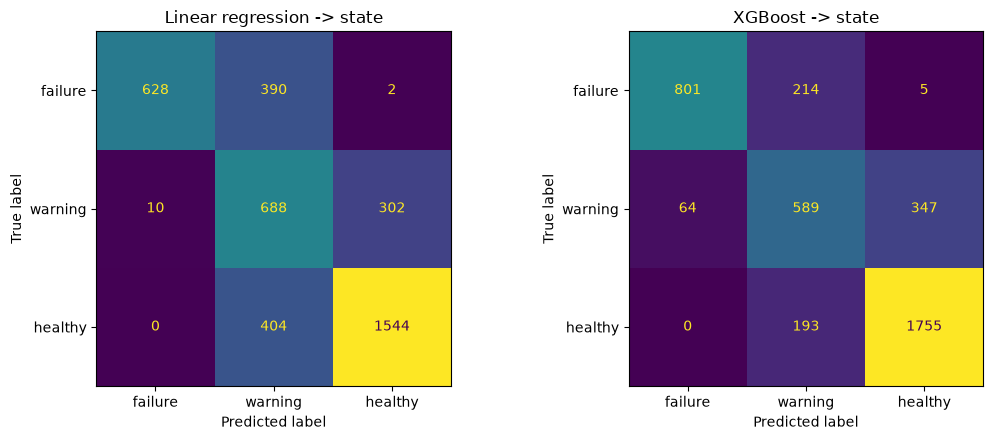

              precision    recall  f1-score   support

     failure       0.93      0.79      0.85      1020
     warning       0.59      0.59      0.59      1000
     healthy       0.83      0.90      0.87      1948

    accuracy                           0.79      3968
   macro avg       0.78      0.76      0.77      3968
weighted avg       0.80      0.79      0.79      3968



In [21]:
pred_lin = np.clip(results["Linear regression"][0].predict(X_test), 0, RUL_CAP)
pred_xgb = np.clip(xgb_best.predict(X_test), 0, RUL_CAP)
labels = list(range(len(STATES)))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (title, p) in zip(ax, [("Linear regression -> state", pred_lin), ("XGBoost -> state", pred_xgb)]):
    ConfusionMatrixDisplay(confusion_matrix(ys_test, rul_to_state_id(p), labels=labels),
                           display_labels=STATES).plot(ax=a, colorbar=False)
    a.set_title(title)
plt.tight_layout(); plt.show()

print(classification_report(ys_test, rul_to_state_id(pred_xgb), target_names=STATES))

### What does XGBoost rely on?

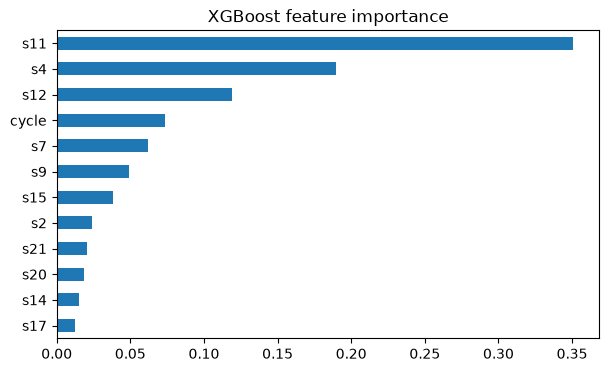

In [22]:
imp = pd.Series(xgb_best.feature_importances_, index=FEATURES).sort_values(ascending=False)
imp.head(12).plot.barh(figsize=(7, 4)).invert_yaxis(); plt.title("XGBoost feature importance"); plt.show()

## 6. Conclusion

Pick the model with the lowest validation RMSE and the best macro-F1 / AUC on the test engines (read the
tables above). The winning pipeline — XGBoost regression with early stopping, then RUL → health state — is
what `train.py` retrains on full_train (train + validation engines) and saves to `model.bin`, and what `predict.py`
serves. Mistakes between *neighbouring* states (warning vs failure, warning vs healthy) are the expected
errors; calling a `failure` engine `healthy` would be the dangerous one — check that cell of the confusion matrix.